# Blok 13: Statystyka w Data Science

- Jezyk: Python
- Biblioteki: numpy, pandas, matplotlib, seaborn, scipy.stats
- Dane: syntetyczne, generowane w tym notatniku (slowniki, listy, DataFrame)

W tym notatniku znajdziesz:
- sekcje tematyczne (zbiory, prawdopodobienstwo, zmienne losowe, rozklady, estymacja, testy),
- kilkadziesiat zadan praktycznych,
- szkielety kodu oznaczone komentarzami `# TODO`.

Rozwiazania krok po kroku znajdziesz w pliku `cwiczenia_solved.ipynb`.


## Opis datasetu

W tym bloku korzystamy z czterech glowowanych (syntetycznych) zbiorow danych.

### 1. Zbior e‑commerce: `df_orders`
- Kazdy wiersz reprezentuje jedno zamowienie w sklepie internetowym.
- Kolumny:
  - `order_id` (int): unikalny identyfikator zamowienia.
  - `user_id` (int): identyfikator uzytkownika.
  - `value` (float): wartosc zamowienia w zl.
  - `channel` (str): kanal pozyskania uzytkownika, np. `ads`, `seo`, `direct`.
  - `is_returned` (bool): czy zamowienie zostalo zwrocone.
  - `sim_period` (str): sztuczna etykieta okresu, np. `before`, `after` (do zadan z testem KS).

### 2. Zbior marketingowy: `df_ab`
- Dane z prostego testu A/B dla kampanii mailingowej.
- Kolumny:
  - `user_id` (int): identyfikator uzytkownika.
  - `group` (str): grupa testowa, `A` lub `B`.
  - `clicked` (int, 0/1): czy uzytkownik kliknal w maila (zmienna Bernoulliego).
  - `converted` (int, 0/1): czy uzytkownik dokonczyl konwersje (np. zakup, rejestracja).

### 3. Zbior fraudowy: `df_fraud`
- Dane o transakcjach platniczych.
- Kolumny:
  - `tx_id` (int): identyfikator transakcji.
  - `amount` (float): kwota transakcji w zl.
  - `is_fraud` (int, 0/1): etykieta fraudu (1 = fraud, 0 = normalna transakcja).
  - `hour` (int): godzina doby (0‑23) wykonania transakcji.

### 4. Zbior HR: `df_hr`
- Dane o pracownikach w kilku zespolach.
- Kolumny:
  - `employee_id` (int): identyfikator pracownika.
  - `team` (str): nazwa zespolu, np. `Sales`, `Support`, `Product`.
  - `tenure_months` (int): staz w firmie w miesiacach.
  - `left` (int, 0/1): czy pracownik odszedl z firmy.

Wszystkie zbiory sa generowane z rozsadnymi rozkladami, tak aby przypominaly realne przypadki biznesowe, ale nie pochodza z prawdziwych danych.


In [1]:
# Importy i generator danych
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set()
np.random.seed(42)

def generate_orders(n_orders=5000):
    user_ids = np.random.randint(1, 1001, size=n_orders)
    channels = np.random.choice(['ads', 'seo', 'direct'], size=n_orders, p=[0.4, 0.35, 0.25])
    base_values = np.random.lognormal(mean=4.0, sigma=0.6, size=n_orders)
    channel_multipliers = np.where(channels == 'ads', 1.1, np.where(channels == 'seo', 1.0, 0.9))
    values = base_values * channel_multipliers
    is_returned = np.random.binomial(1, p=0.08, size=n_orders)
    is_returned = is_returned.astype(bool)
    sim_period = np.random.choice(['before', 'after'], size=n_orders, p=[0.5, 0.5])
    df = pd.DataFrame({
        'order_id': np.arange(1, n_orders + 1),
        'user_id': user_ids,
        'value': values,
        'channel': channels,
        'is_returned': is_returned,
        'sim_period': sim_period
    })
    return df

def generate_ab(n_users=4000):
    user_ids = np.arange(1, n_users + 1)
    groups = np.random.choice(['A', 'B'], size=n_users)
    # Rozne prawdopodobienstwa klikniecia i konwersji dla A i B
    p_click_A, p_click_B = 0.18, 0.22
    p_conv_A, p_conv_B = 0.04, 0.055
    p_click = np.where(groups == 'A', p_click_A, p_click_B)
    p_conv = np.where(groups == 'A', p_conv_A, p_conv_B)
    clicked = np.random.binomial(1, p_click)
    converted = np.random.binomial(1, p_conv)
    df = pd.DataFrame({
        'user_id': user_ids,
        'group': groups,
        'clicked': clicked,
        'converted': converted
    })
    return df

def generate_fraud(n_tx=3000):
    tx_ids = np.arange(1, n_tx + 1)
    hours = np.random.randint(0, 24, size=n_tx)
    base_amounts = np.random.exponential(scale=300, size=n_tx)
    # Dodajemy ogon duzych kwot
    big_spikes = np.random.binomial(1, p=0.02, size=n_tx)
    amounts = base_amounts + big_spikes * np.random.exponential(scale=2000, size=n_tx)
    # Fraud czesciej przy duzych kwotach i w nocy
    p_fraud = 0.01 + 0.04 * (amounts > 1000) + 0.02 * ((hours >= 0) & (hours <= 5))
    p_fraud = np.clip(p_fraud, 0, 0.8)
    is_fraud = np.random.binomial(1, p_fraud)
    df = pd.DataFrame({
        'tx_id': tx_ids,
        'amount': amounts,
        'is_fraud': is_fraud,
        'hour': hours
    })
    return df

def generate_hr(n_emp=800):
    employee_ids = np.arange(1, n_emp + 1)
    teams = np.random.choice(['Sales', 'Support', 'Product', 'Data'], size=n_emp, p=[0.35, 0.3, 0.25, 0.1])
    base_tenure = np.random.exponential(scale=24, size=n_emp)
    team_multipliers = np.where(teams == 'Sales', 0.9,
                                np.where(teams == 'Support', 1.0,
                                         np.where(teams == 'Product', 1.2, 1.3)))
    tenure_months = np.clip(base_tenure * team_multipliers, 1, None).astype(int)
    p_leave = 0.02 + 0.03 * (tenure_months > 24) + 0.03 * (teams == 'Sales')
    p_leave = np.clip(p_leave, 0, 0.7)
    left = np.random.binomial(1, p_leave)
    df = pd.DataFrame({
        'employee_id': employee_ids,
        'team': teams,
        'tenure_months': tenure_months,
        'left': left
    })
    return df

# Generowanie glownych zbiorow danych
df_orders = generate_orders()
df_ab = generate_ab()
df_fraud = generate_fraud()
df_hr = generate_hr()

df_orders.head(), df_ab.head(), df_fraud.head(), df_hr.head()


(   order_id  user_id      value channel  is_returned sim_period
 0         1      103  46.036145  direct        False      after
 1         2      436  43.511883     seo        False     before
 2         3      861  24.428729  direct        False      after
 3         4      271  65.321346     ads        False      after
 4         5      107  65.090011     seo        False      after,
    user_id group  clicked  converted
 0        1     B        0          1
 1        2     A        0          0
 2        3     A        1          0
 3        4     A        0          0
 4        5     A        1          0,
    tx_id      amount  is_fraud  hour
 0      1  393.355410         0    20
 1      2  321.306506         0     0
 2      3  306.231379         0    23
 3      4  724.874981         0    12
 4      5  886.574704         0     1,
    employee_id     team  tenure_months  left
 0            1  Product              4     0
 1            2  Support             27     0
 2           

## Sekcja 1: Operacje na zbiorach i podstawowe prawdopodobienstwo

Zadania w tej sekcji wykorzystuja proste listy, slowniki i male DataFrame, aby zbudowac intuicje zdarzen, sumy, iloczynu i klasycznego prawdopodobienstwa.


### Zadanie 1 – Zdarzenia i zbiory na prostym przykladzie

- Kontekst biznesowy: prosta gra losowa (rzut kostka), analogiczna do losowych zachowan uzytkownikow.
- Cel techniczny: cwiczenie reprezentacji zdarzen jako zbiorow / list i podstawowych operacji (suma, iloczyn, roznica, dopelnienie).
- Poziom trudnosci: 1/5
- Czas: ok. 5‑10 minut
- Wskazowki:
  1. Traktuj wyniki rzutu kostka jako elementy listy od 1 do 6.
  2. Uzyj list comprehension, aby zdefiniowac zdarzenia.
  3. Uzyj operacji na zbiorach Pythona (set) do policzenia sumy i iloczynu.


In [9]:
# Zadanie 1
# Mamy uczciwa kostke do gry: mozliwe wyniki to 1, 2, 3, 4, 5, 6.
# Zdefiniuj nastepujace zdarzenia jako zbiory:
#   A: wypadla liczba parzysta
#   B: wypadla liczba > 3
# Nastepnie policz:
#   - A union B (suma zdarzen)
#   - A intersection B (iloczyn zdarzen)
#   - A bez B (roznica zbiorow)
#   - dopelnienie A wzgl. calej przestrzeni wynikow

omega = set([1, 2, 3, 4, 5, 6])

A = {x for x in omega if x % 2 == 0}
B = {x for x in omega if x > 3}

A_union_B = A.union(B)
A_intersection_B = A.intersection(B)
A_minus_B = A.difference(B)
A_complement = omega.difference(A)

print('A =', A)
print('B =', B)
print('A union B =', A_union_B)
print('A intersection B =', A_intersection_B)
print('A minus B =', A_minus_B)
print('A complement =', A_complement)

A = {2, 4, 6}
B = {4, 5, 6}
A union B = {2, 4, 5, 6}
A intersection B = {4, 6}
A minus B = {2}
A complement = {1, 3, 5}


### Zadanie 2 – Klasyczne prawdopodobienstwo z liczeniem wynikow

- Kontekst biznesowy: losowy wybor uzytkownika i klasyczne P(A) = liczba korzystnych / liczba wszystkich.
- Cel techniczny: policzenie prawdopodobienstwa klasycznego w prostym eksperymencie (kostka, karty itp.).
- Poziom trudnosci: 1/5
- Czas: ok. 5‑10 minut
- Wskazowki:
  1. Skorzystaj z wynikow z zadania 1.
  2. P(A) = len(A) / len(omega).
  3. Pamietaj, ze wyniki sa zakladane jako rownomiernie prawdopodobne.


In [6]:
# Zadanie 2
# Korzystajac z A, B oraz omega z zadania 1 policz:
#   - P(A)
#   - P(B)
#   - P(A union B)
#   - P(A intersection B)
# Zaloz, ze kazdy wynik rzutu kostka jest rownomiernie prawdopodobny.

P_A = len(A) / len(omega)
P_B = len(B) / len(omega)
P_A_union_B = len(A_union_B) / len(omega)
P_A_intersection_B = len(A_intersection_B) / len(omega)

print('P(A) =', P_A)
print('P(B) =', P_B)
print('P(A union B) =', P_A_union_B)
print('P(A intersection B) =', P_A_intersection_B)

P(A) = 0.5
P(B) = 0.5
P(A union B) = 0.6666666666666666
P(A intersection B) = 0.3333333333333333


### Zadanie 3 – Proste prawdopodobienstwo na `df_orders`

- Kontekst biznesowy: sklep internetowy, losowo wybieramy jedno zamowienie.
- Cel techniczny: policzenie prawdopodobienstw z uzyciem DataFrame (proste filtrowanie i len).
- Poziom trudnosci: 2/5
- Czas: ok. 10‑15 minut
- Wskazowki:
  1. Traktuj kazdy wiersz `df_orders` jako wynik eksperymentu.
  2. P(A) ~ liczba wierszy spelniajacych warunek / liczba wszystkich wierszy.
  3. Uzyj masek logicznych `df_orders[mask]`.


In [15]:
# Zadanie 3
# Eksperyment: losowo wybieramy jedno zamowienie z df_orders.
# Zdefiniuj zdarzenia:
#   A: wartosc zamowienia > 300
#   B: zamowienie pochodzi z kanalu 'ads'
#   C: zamowienie nie zostalo zwrocone
# Policz przyblizone prawdopodobienstwa:
#   - P(A)
#   - P(B)
#   - P(C)
#   - P(A and B)
#   - P(A and C)
#   - P(A or B)

n_all = len(df_orders)

mask_A = df_orders['value'] > 300
mask_B = df_orders['channel'] == 'ads'
mask_C = ~df_orders['is_returned']

P_A = len(df_orders[mask_A]) / n_all
P_B = len(df_orders[mask_B]) / n_all
P_C = len(df_orders[mask_C]) / n_all
P_A_and_B = len(df_orders[mask_A & mask_B]) / n_all
P_A_and_C = len(df_orders[mask_A & mask_C]) / n_all
P_A_or_B = len(df_orders[mask_A | mask_B]) / n_all

print('P(A) =', P_A)
print('P(B) =', P_B)
print('P(C) =', P_C)
print('P(A and B) =', P_A_and_B)
print('P(A and C) =', P_A_and_C)
print('P(A or B) =', P_A_or_B)

P(A) = 0.0022
P(B) = 0.4074
P(C) = 0.9194
P(A and B) = 0.0014
P(A and C) = 0.0016
P(A or B) = 0.4082


### Zadanie 4 – Sprawdzenie prostych wlasnosci prawdopodobienstwa

- Kontekst biznesowy: sanity check na wynikach z Zadania 3.
- Cel techniczny: sprawdzenie, czy wyniki sa zgodne z prostymi wlasnosciami prawdopodobienstwa.
- Poziom trudnosci: 2/5
- Czas: ok. 5‑10 minut
- Wskazowki:
  1. Zastanow sie, jakie relacje powinny zachodzic miedzy P(A), P(B), P(A union B), P(A intersection B).
  2. Uzyj funkcji `abs` zeby sprawdzic, czy roznica jest mala (np. < 0.01).
  3. Mozesz napisac proste asercje `assert`.


In [17]:
# Zadanie 4
# Sprawdz, czy przyblizone prawdopodobienstwa z Zadania 3 sa zgodne z nastepujaca wlasnoscia:
#   P(A union B) ~ P(A) + P(B) - P(A intersection B)
# Zbuduj proste sprawdzenie liczbowo (np. roznica bezwzgledna < 0.01).
# Jesli roznica jest za duza, wypisz ostrzezenie.

lhs = P_A_or_B # lewa strona
rhs = P_A + P_B - P_A_and_B  # prawa strona
diff = abs(lhs - rhs)

print('lhs =', lhs)
print('rhs =', rhs)
print('diff =', diff)

assert diff < 0.01, 'Roznica jest zbyt duza'


lhs = 0.4082
rhs = 0.40819999999999995
diff = 5.551115123125783e-17


## Sekcja 2: Prawdopodobienstwo warunkowe i Twierdzenie Bayesa

W tej sekcji pracujemy na malych przykladach oraz zbiorach `df_ab` i `df_fraud`, aby policzyc P(A|B) i zbudowac intuicje Twierdzenia Bayesa.


### Zadanie 5 – Prawdopodobienstwo warunkowe na malej liscie

- Kontekst biznesowy: kampania mailingowa dla kilku uzytkownikow.
- Cel techniczny: policzenie P(kupil | kliknal) na podstawie malych danych w postaci listy slownikow.
- Poziom trudnosci: 1/5
- Czas: ok. 5‑10 minut
- Wskazowki:
  1. Zbuduj liste kilku uzytkownikow recznie (np. 6‑8 elementow).
  2. Zastosuj filtrowanie listy po warunku `clicked == True`.
  3. Policz odsetek tych, ktorzy kupili w podsrednim zbiorze.


In [29]:
users_small = [{'user_id' : x, 'clicked' : np.random.choice([True, False]), 'bought' : np.random.choice([True, False])} for x in range(8)]
users_small

[{'user_id': 0, 'clicked': np.False_, 'bought': np.True_},
 {'user_id': 1, 'clicked': np.False_, 'bought': np.True_},
 {'user_id': 2, 'clicked': np.True_, 'bought': np.False_},
 {'user_id': 3, 'clicked': np.True_, 'bought': np.True_},
 {'user_id': 4, 'clicked': np.True_, 'bought': np.False_},
 {'user_id': 5, 'clicked': np.True_, 'bought': np.False_},
 {'user_id': 6, 'clicked': np.True_, 'bought': np.False_},
 {'user_id': 7, 'clicked': np.False_, 'bought': np.True_}]

In [66]:
# Zadanie 5
# Stworz niewielka liste slownikow reprezentujaca uzytkownikow, np.:
#   {'user_id': 1, 'clicked': True, 'bought': False}
#   {'user_id': 2, 'clicked': True, 'bought': True}
#   ...
# Nastepnie policz prawdopodobienstwo P(bought | clicked).

users_small = [{'user_id' : 1, 'clicked' : np.random.choice([True, False]), 'bought' : np.random.choice([True, False])} for x in range(20)]

df = pd.DataFrame(users_small)
clicked_users = df[df['clicked'] == True]
# display(df)
# display(clicked_users)

p_bought_given_clicked = clicked_users['bought'].sum() / len(clicked_users)

print('P(bought | clicked) ~', p_bought_given_clicked)


P(bought | clicked) ~ 0.5


### Zadanie 6 – Porownanie P(A|B) i P(B|A)

- Kontekst biznesowy: zrozumienie roznicy miedzy P(kupil | kliknal) a P(kliknal | kupil).
- Cel techniczny: policzenie obu prawdopodobienstw na tym samym, malym zbiorze i porownanie.
- Poziom trudnosci: 2/5
- Czas: ok. 10‑15 minut
- Wskazowki:
  1. Uzyj `users_small` z Zadania 5.
  2. Policz P(bought | clicked) oraz P(clicked | bought).
  3. Zastanow sie, dlaczego te wartosci sa zwykle rozne.


In [67]:
# Zadanie 6
# Korzystajac z users_small:
#   - oblicz P(bought | clicked) -> P(bought & clicked) / P(clicked)
#   - oblicz P(clicked | bought) -> P(bought | clicked) * P(clicked) / P(bought)
# i porownaj te wartosci.


p_clicked = df['clicked'].sum() / len(df)
p_bought = df['bought'].sum() / len(df)
p_bought_given_clicked = clicked_users['bought'].sum() / len(clicked_users)
p_clicked_given_bought = p_bought_given_clicked * p_clicked / p_bought

print('P(bought | clicked) =', p_bought_given_clicked)
print('P(clicked | bought) =', p_clicked_given_bought)


P(bought | clicked) = 0.5
P(clicked | bought) = 0.33333333333333337


### Zadanie 7 – Bayes na przykladzie fraudow

- Kontekst biznesowy: zespol fraudowy analizuje transakcje powyzej 1000 zl.
- Cel techniczny: policzenie P(fraud | amount > 1000) z df_fraud oraz P(amount > 1000 | fraud) i P(fraud).
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Stworz zmienna logiczna `high_amount` oznaczajaca kwoty > 1000.
  2. Policz P(fraud), P(high_amount) oraz P(high_amount | fraud).
  3. Uzyj wzoru Bayesa, aby obliczyc P(fraud | high_amount) i porownaj z bezposrednim liczeniem z danych.


In [71]:
df_fraud

,tx_id,amount,is_fraud,hour,high_amount
0,1,393.355410,0,20,False
1,2,321.306506,0,0,False
2,3,306.231379,0,23,False
3,4,724.874981,0,12,False
4,5,886.574704,0,1,False
...,...,...,...,...,...
2995,2996,112.095916,0,18,False
2996,2997,807.975196,1,10,False
2997,2998,123.603666,0,8,False
2998,2999,119.550561,0,5,False


In [83]:
# Zadanie 7
# Na df_fraud policz:
#   - P(fraud)
#   - P(high_amount) dla high_amount: amount > 1000
#   - P(high_amount | fraud)
#   - P(fraud | high_amount) na dwa sposoby:
#       a) bezposrednio z danych
#       b) z wykorzystaniem wzoru Bayesa

df_fraud['high_amount'] = df_fraud['amount'] > 1000

P_fraud = df_fraud['is_fraud'].mean()
P_high = df_fraud['high_amount'].mean()
P_high_given_fraud = df_fraud[df_fraud['is_fraud'] == 1]['high_amount'].mean()

P_fraud_given_high_direct = df_fraud[df_fraud['high_amount']]['is_fraud'].mean()

P_fraud_given_high_bayes = P_high_given_fraud * P_fraud / P_high

print('P(fraud) =', P_fraud)
print('P(high_amount) =', P_high)
print('P(high_amount | fraud) =', P_high_given_fraud)
print('P(fraud | high_amount) direct =', P_fraud_given_high_direct)
print('P(fraud | high_amount) Bayes =', P_fraud_given_high_bayes)


P(fraud) = 0.018
P(high_amount) = 0.05
P(high_amount | fraud) = 0.12962962962962962
P(fraud | high_amount) direct = 0.04666666666666667
P(fraud | high_amount) Bayes = 0.04666666666666666


### Zadanie 8 – Prawdopodobienstwo calkowite na `df_ab`

- Kontekst biznesowy: globalny wspolczynnik konwersji kampanii z roznych grup.
- Cel techniczny: zastosowanie wzoru na prawdopodobienstwo calkowite P(A) = sum P(A | Bi) * P(Bi).
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. A = zdarzenie 'converted == 1'.
  2. Zupleny podzial przestrzeni: grupy B1 = 'A', B2 = 'B'.
  3. Policz P(A), P(A | 'A'), P(A | 'B'), P('A'), P('B') i sprawdz, czy zgadza sie wzor.


In [97]:
# Zadanie 8
# Na zbiorze df_ab:
#   - oblicz globalny wspolczynnik konwersji P(A): odsetek wierszy z converted == 1
#   - oblicz P(A | group = 'A') i P(A | group = 'B')
#   - oblicz P(group = 'A') i P(group = 'B')
#   - sprawdz, czy P(A) ~ P(A|'A')*P('A') + P(A|'B')*P('B')

P_A_global = df_ab['converted'].mean()
P_A_given_A = df_ab[df_ab['group'] == 'A']['converted'].mean()
P_A_given_B = df_ab[df_ab['group'] == 'B']['converted'].mean()
P_group_A = (df_ab['group'] == 'A').mean()
P_group_B = (df_ab['group'] == 'B').mean()

P_A_total = (P_A_given_A * P_group_A) + (P_A_given_B * P_group_B) # P(A) z wzoru na prawdopodobienstwo calkowite
diff = P_A_global - P_A_total

print('P(A) global =', P_A_global)
print('P(A) z prawd. calkowitego =', P_A_total)
print('Roznica =', diff)


P(A) global = 0.05
P(A) z prawd. calkowitego = 0.05
Roznica = 0.0


## Sekcja 3: Zmienne losowe i parametry rozkladu

W tej sekcji patrzymy na zmienne losowe (wartosc koszyka, liczba zamowien, staz w firmie) i liczymy ich parametry: mean, median, variance, std, kwantyle itp.


### Zadanie 9 – Statystyki opisowe wartosci koszyka

- Kontekst biznesowy: podstawowa analiza wartosci zamowien w e‑commerce.
- Cel techniczny: policzenie mean, median, std, min, max, kwantyli dla `df_orders['value']`.
- Poziom trudnosci: 1/5
- Czas: ok. 10‑15 minut
- Wskazowki:
  1. Uzyj metod `mean`, `median`, `std`, `min`, `max`, `quantile`.
  2. Zbuduj prosty slownik z wynikami, zeby miec je w jednym miejscu.
  3. Zinterpretuj roznice miedzy mean a median.


{'mean': np.float64(66.11846178500798),
 'median': np.float64(54.46454465965353),
 'std': np.float64(44.238993112101475),
 'min': np.float64(7.559138798042526),
 'max': np.float64(503.5833231642914),
 'q1': np.float64(36.37488491773453),
 'q3': np.float64(82.9273708417723)}

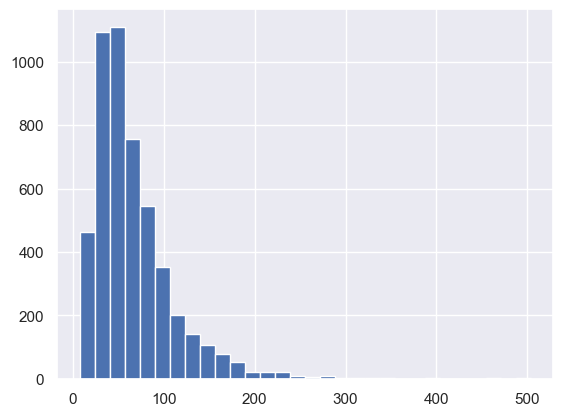

In [120]:
# Zadanie 9
# Policz podstawowe statystyki opisowe dla wartosci zamowien w df_orders.

values = df_orders['value']

stats_orders = {
    'mean': values.mean(),
    'median': values.median(),
    'std': values.std(),
    'min': values.min(),
    'max': values.max(),
    'q1': values.quantile(0.25),
    'q3': values.quantile(0.75)
}

display(stats_orders)
plt.hist(values, bins=30)
plt.show()

### Zadanie 10 – Zmienna losowa: liczba zamowien na uzytkownika

- Kontekst biznesowy: liczba zamowien na klienta (lojalnosc, aktywnosc).
- Cel techniczny: policzenie rozkladu liczby zamowien na uzytkownika (zmienna dyskretna) i podstawowych parametrow.
- Poziom trudnosci: 2/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Uzyj `groupby('user_id').size()` do policzenia liczby zamowien na uzytkownika.
  2. Potraktuj wynik jako zmienna losowa i policz mean, std oraz histogram.
  3. Zastanow sie, czy przypomina to jakis znany rozklad (np. Poissona).


In [111]:
df_orders.head()

,order_id,user_id,value,channel,is_returned,sim_period
0,1,103,46.036145,direct,False,after
1,2,436,43.511883,seo,False,before
2,3,861,24.428729,direct,False,after
3,4,271,65.321346,ads,False,after
4,5,107,65.090011,seo,False,after


MIN | MAX = 1 | 14
Srednia liczba zamowien na usera = 5.055611729019211
Std liczby zamowien na usera = 2.325257670390197


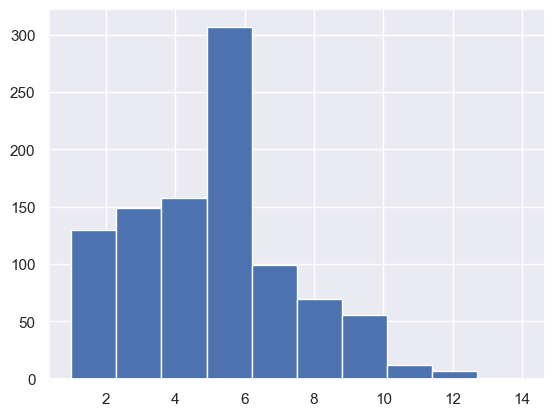

In [145]:
# Zadanie 10
# Policz ile zamowien ma kazdy user_id, a nastepnie potraktuj to jako zmienna losowa.

orders_per_user = df_orders.groupby('user_id').size()

mean_orders = orders_per_user.mean()
std_orders = orders_per_user.std()

print('MIN | MAX =', orders_per_user.min(), '|', orders_per_user.max())
print('Srednia liczba zamowien na usera =', mean_orders)
print('Std liczby zamowien na usera =', std_orders)

plt.hist(orders_per_user)
plt.show()


### Zadanie 11 – Kwantyle i IQR dla stazu w firmie

- Kontekst biznesowy: analiza stazu pracownikow w firmie.
- Cel techniczny: policzenie kwantyli i rozstepu miedzykwartylowego (IQR) dla `df_hr['tenure_months']`.
- Poziom trudnosci: 1/5
- Czas: ok. 10 minut
- Wskazowki:
  1. Skorzystaj z `quantile` dla wartosci 0.25, 0.5, 0.75.
  2. Oblicz IQR = Q3 - Q1.
  3. Zastanow sie, jak IQR moze pomoc w wykrywaniu outliers.


In [ ]:
# Zadanie 11
# Policz Q1, mediane, Q3 oraz IQR dla tenure_months w df_hr.

tenure = df_hr['tenure_months']

# TODO: policz kwantyle
Q1 = None
median = None
Q3 = None
IQR = None

print('Q1 =', Q1)
print('Mediana =', median)
print('Q3 =', Q3)
print('IQR =', IQR)


### Zadanie 12 – Skosnosc i kurtoza

- Kontekst biznesowy: czy rozklad wartosci zamowien ma dlugi ogon i jak bardzo jest spiczasty.
- Cel techniczny: policzenie skosnosci i kurtozy dla `df_orders['value']` oraz interpretacja.
- Poziom trudnosci: 2/5
- Czas: ok. 10‑15 minut
- Wskazowki:
  1. Uzyj metod `skew()` i `kurt()` z pandas.
  2. Dodatnia skosnosc oznacza dlugi ogon w prawo (kilka bardzo duzych wartosci).
  3. Kurtoza dodatnia oznacza bardziej spiczasty rozklad niz normalny.


In [ ]:
# Zadanie 12
# Policz skosnosc i kurtoze dla wartosci zamowien.

# TODO: policz skewness i kurtosis
skew_value = None
kurt_value = None

print('Skosnosc (skew) =', skew_value)
print('Kurtoza (kurt) =', kurt_value)


## Sekcja 4: Rozklady prawdopodobienstwa i symulacja

W tej sekcji korzystamy z numpy i scipy.stats, aby symulowac i wizualizowac proste rozklady (Bernoulli, dwumianowy, Poissona, jednostajny, normalny).


### Zadanie 13 – Bernoulli i dwumianowy na danych A/B

- Kontekst biznesowy: klikniecie w kampanii jako zmienna Bernoulliego.
- Cel techniczny: porownanie empirycznego wspolczynnika klikniec z symulacja dwumianowa.
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Policz empiryczny CTR dla grupy A.
  2. Zasymuluj wiele kampanii (np. 1000) z rozkladem dwumianowym o tym samym n i p.
  3. Narysuj histogram CTR z symulacji i porownaj z empirycznym.


In [ ]:
# Zadanie 13
# Dla grupy A w df_ab:
#   - policz empiryczny CTR (srednia clicked)
#   - zasymuluj np. 1000 kampanii z rozkladem dwumianowym
#   - porownaj empiryczny CTR z rozkladem z symulacji

# TODO: wyciagnij dane grupy A i policz empiryczny CTR
df_A = df_ab[df_ab['group'] == 'A']
n_A = len(df_A)
ctr_emp_A = None

# TODO: zasymuluj CTR w wielu kampaniach
n_sim = 1000
ctr_sims = None  # np. np.random.binomial(...)

# TODO (opcjonalnie): narysuj histogram ctr_sims
# plt.hist(...)

print('Empiryczny CTR A =', ctr_emp_A)


### Zadanie 14 – Rozklad Poissona dla liczby transakcji

- Kontekst biznesowy: liczba transakcji na godzine w systemie platnosci.
- Cel techniczny: symulacja rozkladu Poissona i porownanie z empiria.
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Z df_fraud policz srednia liczbe transakcji na godzine.
  2. Uzyj tej sredniej jako parametru lambda w rozkladzie Poissona.
  3. Porownaj histogram empiryczny i symulowany.


In [ ]:
# Zadanie 14
# 1. Policz srednia liczbe transakcji na godzine na podstawie df_fraud.
# 2. Zasymuluj rozklad Poissona o takiej samej sredniej.
# 3. Porownaj histogram liczby transakcji (empiryczny vs symulacja).

# TODO: policz liczbe transakcji per hour
tx_per_hour = None
lambda_hat = None

# TODO: symulacja Poissona
n_sim = 1000
sim_counts = None

print('Lambda Poissona (srednia liczba transakcji na godzine) =', lambda_hat)


### Zadanie 15 – Jednostajny rozklad czasu w ciagu dnia

- Kontekst biznesowy: uproszczony model, w ktorym zdarzenia moga wystepowac w dowolnym momencie w ciagu godziny.
- Cel techniczny: symulacja rozkladu jednostajnego i wizualizacja.
- Poziom trudnosci: 1/5
- Czas: ok. 5‑10 minut
- Wskazowki:
  1. Uzyj `np.random.uniform(0, 60, size=...)` do symulacji minuty w ciagu godziny.
  2. Narysuj histogram i zobacz, czy jest w miare plaski.
  3. Porownaj z rozkladem np. normalnym (dla porownania ksztaltu).


In [ ]:
# Zadanie 15
# Zasymuluj np. 2000 momentow w ciagu godziny (w minutach) z rozkladu jednostajnego [0, 60].
# Narysuj histogram i zinterpretuj ksztalt.

# TODO: symulacja
minutes = None

# TODO (opcjonalnie): histogram
# plt.hist(...)


### Zadanie 16 – Rozklad normalny jako model wartosci koszyka

- Kontekst biznesowy: przyblizanie rozkladu wartosci zamowien rozkladem normalnym.
- Cel techniczny: policzenie sredniej i odchylenia standardowego oraz zasymulowanie normalnego rozkladu do porownania.
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Uzyj `df_orders['value']` do wyznaczenia mean i std.
  2. Wygeneruj z `np.random.normal` probke o tej samej wielkosci.
  3. Porownaj histogramy oryginalnych danych i symulacji.


In [ ]:
# Zadanie 16
# 1. Policz mean i std wartosci zamowien.
# 2. Zasymuluj rozklad normalny o tych parametrach i tej samej wielkosci probki.
# 3. Porownaj histogramy.

values = df_orders['value']

# TODO: policz mean i std
mu = None
sigma = None

        
# TODO: symulacja normalna
sim_normal = None

# TODO (opcjonalnie): narysuj dwa histogramy obok siebie


## Sekcja 5: Estymacja i centralne twierdzenie graniczne (CLT)

Teraz przechodzimy do estymacji parametrow (np. sredniej) oraz obserwujemy, jak rozkladaja sie srednie z wielu prob (intuicja CLT).


### Zadanie 17 – Rozklad srednich z probek

- Kontekst biznesowy: jak bardzo waha sie srednia wartosc koszyka, gdy patrzymy na rozne losowe probki klientow.
- Cel techniczny: losowanie wielu probek z `df_orders['value']` i liczenie ich srednich.
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Wybierz rozmiar probki, np. 50 lub 100.
  2. W petli np. 500 razy losuj probke bez zwracania i licz srednia.
  3. Narysuj histogram srednich i zobacz, czy przypomina normalny.


In [ ]:
# Zadanie 17
# Wylosuj wiele probek wartosci zamowien i policz rozklad srednich.

values = df_orders['value'].values

# TODO: parametry symulacji
sample_size = 100
n_samples = 500

sample_means = []

# TODO: petla losujaca probki i liczaca srednie
for i in range(n_samples):
    pass

sample_means = np.array(sample_means)

# TODO (opcjonalnie): rysunek histogramu sample_means
# plt.hist(...)


### Zadanie 18 – Bled sredniej i standard error

- Kontekst biznesowy: jak pewni jestesmy estymowanej sredniej wartosci koszyka.
- Cel techniczny: policzenie standard deviation i standard error sredniej.
- Poziom trudnosci: 2/5
- Czas: ok. 10‑15 minut
- Wskazowki:
  1. Standard error (SE) sredniej ~ sigma / sqrt(n).
  2. Uzyj sigma z danych oraz liczby obserwacji.
  3. Porownaj SE dla roznych rozmiarow probki (np. 50 vs 500).


In [ ]:
# Zadanie 18
# Policz standard error sredniej wartosci zamowien dla roznych rozmiarow probki.

values = df_orders['value']

# TODO: policz sigma (odchylenie standardowe) dla calej populacji
sigma_all = None

for n in [50, 100, 500, 1000]:
    # TODO: policz SE = sigma_all / sqrt(n)
    SE = None
    print('n =', n, 'SE =', SE)


### Zadanie 19 – Prostokatny przedzial ufnosci dla sredniej

- Kontekst biznesowy: przyblizony przedzial, w ktorym lezy prawdziwa srednia wartosc koszyka.
- Cel techniczny: policzenie mean oraz przedzialu mean ± 1.96 * SE.
- Poziom trudnosci: 3/5
- Czas: ok. 15‑20 minut
- Wskazowki:
  1. Uzyj wartosci sigma i n dla calego zbioru.
  2. Dla uproszczenia przyjmijmy normalne przyblizenie.
  3. To jest przyblizony 95% przedzial ufnosci.


In [ ]:
# Zadanie 19
# Policz przyblizony 95% przedzial ufnosci dla sredniej wartosci zamowien.

values = df_orders['value']
n = len(values)

# TODO: policz mean i std
mean_val = None
std_val = None
SE = None

# TODO: policz dolna i gorna granice CI
z = 1.96
lower = None
upper = None

print('Srednia =', mean_val)
print('Przedzial (95%) ~ [', lower, ',', upper, ']')


## Sekcja 6: Testy statystyczne

W tej sekcji przeprowadzimy kilka typowych testow statystycznych: test t-Studenta, test chi-kwadrat, test Kolmogorova-Smirnova.


### Zadanie 20 – Test t-Studenta: porownanie sredniej wartosci koszyka dla kanalow

- Kontekst biznesowy: czy kanal `ads` generuje wyzsza srednia wartosc zamowienia niz `seo`.
- Cel techniczny: wykonanie testu t-Studenta dla dwoch niezaleznych prob.
- Poziom trudnosci: 3/5
- Czas: ok. 20–25 minut
- Wskazowki:
  1. Wydziel dwie serie: wartosci zamowien dla kanału `ads` i `seo`.
  2. Uzyj `stats.ttest_ind` (z `equal_var=False`).
  3. Zinterpretuj p-wartosc w kontekscie biznesowym.


In [ ]:
# Zadanie 20
# Przeprowadz test t-Studenta porownujacy srednia wartosc zamowienia dla kanalow 'ads' i 'seo'.

# TODO: wydziel probki
values_ads = None
values_seo = None

# TODO: wykonaj test t
t_stat = None
p_value = None

print('t_stat =', t_stat)
print('p_value =', p_value)

# TODO: krotki komentarz (w komentarzu) jak bys to zinterpretowal biznesowo
# np. jesli p_value < 0.05, to ...


### Zadanie 21 – Test chi-kwadrat: kanal pozyskania vs konwersja

- Kontekst biznesowy: czy kanal pozyskania (ads, seo, direct) wplywa na konwersje.
- Cel techniczny: zbudowanie tabeli kontyngencji i wykonanie testu chi-kwadrat.
- Poziom trudnosci: 3/5
- Czas: ok. 20–25 minut
- Wskazowki:
  1. Z df_ab zbuduj `pd.crosstab(df_ab['group'], df_ab['converted'])` lub podobna tabele.
  2. Uzyj `stats.chi2_contingency`.
  3. Zinterpretuj p-wartosc.


In [ ]:
# Zadanie 21
# Sprawdz, czy grupa A/B jest powiazana z konwersja (converted).

# TODO: zbuduj tabele kontyngencji
contingency = None

# TODO: wykonaj test chi-kwadrat
chi2 = None
p_value = None
dof = None
expected = None

print('Tabela kontyngencji:')
print(contingency)
print('chi2 =', chi2)
print('p_value =', p_value)


### Zadanie 22 – Test Kolmogorova-Smirnova: okres 'before' vs 'after'

- Kontekst biznesowy: porownanie rozkladu wartosci koszyka przed i po kampanii.
- Cel techniczny: uzycie testu KS do porownania dwoch rozkladow.
- Poziom trudnosci: 3/5
- Czas: ok. 20–25 minut
- Wskazowki:
  1. Uzyj kolumny `sim_period` z df_orders (before vs after).
  2. Porownaj rozklad `value` w obu grupach.
  3. Zinterpretuj wynik testu.


In [ ]:
# Zadanie 22
# Porownaj rozklad wartosci zamowien dla okresu 'before' i 'after' przy uzyciu testu KS.

from scipy.stats import ks_2samp

# TODO: wydziel wartosci dla obu okresow
values_before = None
values_after = None

# TODO: wykonaj test KS
stat = None
p_value = None

print('KS stat =', stat)
print('p_value =', p_value)


### Zadanie 23 – Test KS vs rozklad normalny

- Kontekst biznesowy: sprawdzenie, czy wartosci zamowien mozna przyblizyc rozkladem normalnym.
- Cel techniczny: testowanie hipotezy, ze dane pochodza z normalnego rozkladu N(mu, sigma).
- Poziom trudnosci: 4/5
- Czas: ok. 20–25 minut
- Wskazowki:
  1. Wyznacz mean i std wartosci zamowien.
  2. Wygeneruj z `np.random.normal` probke o tej samej wielkosci.
  3. Uzyj `ks_2samp` do porownania obu rozkladow.


In [ ]:
# Zadanie 23
# Sprawdz, czy rozklad wartosci zamowien jest zblizony do normalnego N(mu, sigma).

values = df_orders['value']

# TODO: policz mean i std
mu = None
sigma = None

# TODO: zasymuluj rozklad normalny o tych parametrach
sim_normal = None

# TODO: wykonaj test KS
stat = None
p_value = None

print('KS stat =', stat)
print('p_value =', p_value)


## Sekcja 7: Mini-projekty

Na koniec dwie wieksze, bardziej otwarte aktywnosci, ktore lacza wiekszosc pojec z bloku.


### Zadanie 24 (mini-projekt) – Pelny A/B test kampanii

- Kontekst biznesowy: zespol marketingu chce zdecydowac, ktora wersje kampanii zostawic (A czy B).
- Cel techniczny:
  1. Analiza opisowa df_ab (CTR, CR, rozklady po grupach).
  2. Testy statystyczne (np. test dla roznicy konwersji).
  3. Interpretacja wynikow w jezyku biznesowym.
- Poziom trudnosci: 4/5
- Czas: ok. 30‑40 minut
- Wskazowki:
  1. Najpierw policz i narysuj podstawowe metryki (CTR, CR) dla A i B.
  2. Uzyj testu t lub innego odpowiedniego testu dla porownania roznic (przy prostym zalozeniu).
  3. Na koniec opisz w komentarzu, ktora grupe bys wybral i dlaczego.


In [ ]:
# Zadanie 24 (mini-projekt)
# Przeprowadz pelny mini A/B test na df_ab.
# Proponowane kroki (ale mozesz je modyfikowac):
# 1. Policz CTR i CR dla grup A i B.
# 2. Narysuj wykresy porownujace te metryki.
# 3. Wykonaj wybrany test statystyczny porownujacy konwersje / klikniecia.
# 4. Sformuluj rekomendacje biznesowa (w komentarzu tekstowym).

# TODO: krok 1 – metryki opisowe

# TODO: krok 2 – wizualizacja

# TODO: krok 3 – test statystyczny

# TODO: krok 4 – komentarz tekstowy w stylu:
# "Na podstawie danych rekomenduje grupe ... poniewaz ..."


### Zadanie 25 (mini-projekt) – Roznice miedzy zespolami w HR

- Kontekst biznesowy: dzial HR chce sprawdzic, czy zespol `Sales` ma inny staz i rotacje niz pozostale zespoly.
- Cel techniczny:
  1. Analiza opisowa stazu i rotacji per zespol.
  2. Testy porownawcze (np. test t dla sredniego stazu, chi-kwadrat dla rotacji).
  3. Sformulowanie wnioskow.
- Poziom trudnosci: 4/5
- Czas: ok. 30‑40 minut
- Wskazowki:
  1. Porownaj `tenure_months` w `Sales` vs reszta.
  2. Policz odsetek `left == 1` w zespolach.
  3. Zastosuj odpowiednie testy i opisz wyniki.


In [ ]:
# Zadanie 25 (mini-projekt)
# Przeanalizuj roznice miedzy zespolem Sales a innymi zespolami w df_hr.
# Proponowane kroki:
# 1. Porownanie statystyk opisowych stazu (tenure_months) dla Sales vs reszta.
# 2. Test t-Studenta dla stazu.
# 3. Analiza rotacji (odsetek left == 1) i test chi-kwadrat.
# 4. Wnioski biznesowe.

# TODO: krok 1 – statystyki opisowe

# TODO: krok 2 – test t

# TODO: krok 3 – test chi-kwadrat dla rotacji

# TODO: krok 4 – komentarz tekstowy z wnioskami


### Zadanie 26 (opcjonalne) – Zaprojektuj wlasny mini‑test statystyczny

- Kontekst biznesowy: dowolny scenariusz (e‑commerce, marketing, fraud, HR) na podstawie dostepnych danych.
- Cel techniczny: samodzielne zaprojektowanie pytania badawczego, dobranie testu i interpretacja wyniku.
- Poziom trudnosci: 4/5
- Czas: ok. 20‑30 minut
- Wskazowki:
  1. Wybierz interesujaca Cie zaleznosc (np. `is_returned` vs `channel`, `is_fraud` vs `hour` itp.).
  2. Zdefiniuj jasno hipotezy H0 i H1.
  3. Dobierz odpowiedni test (t, chi-kwadrat, KS lub inny z scipy.stats).
  4. Napisz krotki raport w komentarzu.


In [ ]:
# Zadanie 26 (opcjonalne)
# Zaprojektuj i wykonaj wlasny test statystyczny na jednym z dostepnych zbiorow:
# - df_orders
# - df_ab
# - df_fraud
# - df_hr
# Opisz krotko hipotezy (H0, H1), zastosuj test i zinterpretuj wynik.

# TODO: Twoj pomysl na analize
